# Setup Notebook

In [3]:
#path configuration
import os
import sys

#data manipulation
import pandas as pd
import numpy as np
from datetime import datetime
import ast

#model evaluation
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, auc, classification_report
from sklearn.calibration import calibration_curve
from sklearn.calibration import CalibratedClassifierCV


#boruta
from boruta import BorutaPy

#data visualization
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

#shap
import shap

#import warning
import warnings
warnings.filterwarnings("ignore")

#reference seed
seed = 42
np.random.seed(seed)

#Import Preprocessing Functions
# from ipynb.fs.full.preprocessing_functions import *
# from ipynb.fs.full.modeling_functions import *
# from ipynb.fs.full.experiment_pipeline import *

from preprocessing_functions import *
from modeling_functions import *
from experiment_pipeline import *

# Import Notebooks and Dataframe

In [4]:
# Import DataFrame
df_exp = pd.read_csv("data/df_exp_simulation.csv").drop(columns = "Unnamed: 0")
print(f"Amount of experiments: {len(df_exp)}")

#read original dpi df
df_dpi = pd.read_csv("data/df_dpi.csv")

#Visualize dataframe
df_exp.head()

Amount of experiments: 1728


,initial_date,final_date,time_interval,create_lag_features_abs,create_lag_features_rel,list_lag_features,list_columns_filter,seed,test_size,remove_correlation,...,best_params,scoring,max_evals,timeout,cv,score_train,score_test,score_train_rank,score_test_rank,Period
0,0,100,1,True,False,[3],NaN,42,0.25,False,...,"{'max_depth': 6, 'min_samples_leaf': 0.005, 'm...",roc_auc,60,600,5,0.768492,0.790233,173.0,1.0,(0-100]
1,0,100,1,True,False,[3],NaN,42,0.25,False,...,"{'alpha': 0.0, 'colsample_bytree': 0.789966965...",roc_auc,60,3600,5,0.768348,0.790086,175.0,2.0,(0-100]
2,0,100,1,True,False,[3],NaN,42,0.25,True,...,"{'max_depth': 6, 'min_samples_leaf': 0.005, 'm...",roc_auc,60,600,5,0.768943,0.789737,170.0,3.0,(0-100]
3,0,100,1,True,False,[5],NaN,42,0.25,True,...,"{'alpha': 0.0, 'colsample_bytree': 0.620714883...",roc_auc,60,3600,5,0.765992,0.789701,191.0,4.0,(0-100]
4,0,100,5,True,False,[3],NaN,42,0.25,True,...,"{'max_depth': 5, 'min_samples_leaf': 0.005, 'm...",roc_auc,60,600,5,0.767744,0.789695,178.0,5.0,(0-100]


# New Iteration Functions
- Obtain the model and training dataset of a specific simulation
- This will be used for Features Selection and Feature Importance

## Obtain Experiment Parameters

In [5]:
def obtain_experiment_parameters(df_exp,
                                 index_df):
  
  """
  Obtain all the preprocessing and modeling parameters of a specific experiment

  Parameters:
    df_exp: dataframe with experiment parameters
    index_df: index of the dataframe to obtain the information

  Return:
    dict_parameters: dictionary with the experiment parameters
  """

  #create dictionary with all parameters
  df_exp_dict = df_exp.iloc[index_df].to_dict()

  #seed
  seed = df_exp_dict["seed"]

  #final date and time interval
  initial_date = df_exp_dict["initial_date"]
  final_date = df_exp_dict["final_date"]
  time_interval = df_exp_dict["time_interval"]

  #feature engineering
  create_lag_features_abs = df_exp_dict["create_lag_features_abs"]
  create_lag_features_rel = df_exp_dict["create_lag_features_rel"]

  if isinstance(df_exp_dict["list_lag_features"], list):
    list_lag_features = df_exp_dict["list_lag_features"]
  else:
    try:
      list_lag_features = ast.literal_eval(df_exp_dict["list_lag_features"])
    except:
      list_lag_features = None

  if isinstance(df_exp_dict["list_columns_filter"], list):
    list_columns_filter = df_exp_dict["list_columns_filter"]
  else:
    try:
      list_columns_filter = ast.literal_eval(df_exp_dict["list_columns_filter"])
    except:
      list_columns_filter = None

  #train test split
  test_size = df_exp_dict["test_size"]

  #remove correlation
  remove_correlation = df_exp_dict["remove_correlation"]

  if isinstance(df_exp_dict["remove_correlation_params"], dict):
    remove_correlation_params = df_exp_dict["remove_correlation_params"]
  else:
    try:
      remove_correlation_params = ast.literal_eval(df_exp_dict["remove_correlation_params"])
    except:
      remove_correlation_params = None

  #rebalancement
  apply_rebalance_strategy = df_exp_dict["apply_rebalance_strategy"]
  if isinstance(df_exp_dict["rebalance_params"], dict):
    rebalance_params = df_exp_dict["rebalance_params"]
  else:
    try:
      rebalance_params = ast.literal_eval(df_exp_dict["rebalance_params"])
    except:
      rebalance_params = None

  #FA
  apply_fa_bool = df_exp_dict["apply_fa"]
  if isinstance(df_exp_dict["fa_params"], dict):
    fa_params = df_exp_dict["fa_params"]
  else:
    try:
      fa_params = ast.literal_eval(df_exp_dict["fa_params"])
    except:
      fa_params = None

  #model
  model = df_exp_dict["model"]

  #best_params with the model
  if isinstance(df_exp_dict["best_params"], dict):
    best_params = df_exp_dict["best_params"]
  else:
    best_params = ast.literal_eval(df_exp_dict["best_params"])
  best_params["classifier_name"] = df_exp_dict["model"]

  #scoring
  scoring = df_exp_dict["scoring"]
  
  #cv
  cv = df_exp_dict["cv"]

  # max_evals
  max_evals = df_exp_dict["max_evals"]

  #timeout
  timeout = df_exp_dict["timeout"]

  #train score
  score_train = df_exp_dict["score_train"]

  #test score
  score_test = df_exp_dict["score_test"]

  #create dictionary parameters
  dict_parameters = {"seed": seed, 
                     "initial_date": initial_date, 
                     "final_date": final_date, 
                     "time_interval": time_interval,
                     "create_lag_features_abs": create_lag_features_abs, 
                     "create_lag_features_rel": create_lag_features_rel, 
                     "list_lag_features": list_lag_features, 
                     "list_columns_filter": list_columns_filter,
                     "test_size": test_size, 
                     "remove_correlation": remove_correlation, 
                     "remove_correlation_params": remove_correlation_params,
                     "apply_fa_bool": apply_fa_bool, 
                     "fa_params": fa_params,
                     "apply_rebalance_strategy": apply_rebalance_strategy,
                     "rebalance_params": rebalance_params,
                     "model": model,
                     "best_params": best_params, 
                     "scoring": scoring, 
                     "cv": cv,
                     "max_evals": max_evals, 
                     "timeout": timeout,
                     "score_train": score_train,
                     "score_test": score_test}

  return dict_parameters

## Reproduce Results

In [6]:
def reproduce_results(df_dpi,
                      dict_parameters):
    """
    Reproduce the results of a model, for a specific set of parameters

    Parameters:
        df_dpi: dataframe with dpi information
        dict_parameters: dictionary with the experiment parameters

    Return:
        X_train: feature training dataset
        y_train: response training dataset
        X_test: feature testing dataset
        y_test: response testing dataset
        model_classifier: trained model
    """
    
    #create preprocessing dictionary
    list_remove = ["best_params", "scoring", "cv", "max_evals", "timeout", "model", "score_train", "score_test"]
    dict_preprocessing = dict_parameters.copy()
    dict_preprocessing = {key: value for key, value in dict_preprocessing.items() if key not in list_remove}

    #preprocess and separate dataframe
    X_train, X_test, y_train, y_test, df_experiment = preprocess_dataframe(df_dpi,
                                                                            **dict_preprocessing)

    #instantiate the model with best hyperparameters
    best_params_classifier = dict_parameters["best_params"]
    model_classifier = instantiate_model(best_params_classifier)

    #fit the model to training dataset
    model_classifier.fit(X_train, y_train.values.ravel())

    return X_train, y_train, X_test, y_test, model_classifier

## Run Boruta

In [7]:
def run_boruta(model_classifier,
               X_train,
               y_train):
    """
    Run the boruta technique to select the best features

    Parameters:
        model_classifier: trained model
        X_train: feature training dataset
        y_train: response training dataset

    Return:
        list_columns_filter: list of selected features
    """

    #instantiate boruta
    boruta_classifier = BorutaPy(estimator = model_classifier,
                                n_estimators = "auto",
                                alpha = 0.01,
                                max_iter = 300,
                                random_state = 42,
                                verbose = -1)

    #feat boruta
    boruta_classifier = boruta_classifier.fit(X_train.values, y_train.values)

    #create dataframe with feature selection information
    df_features_boruta = pd.DataFrame(data = {"feature": X_train.columns,
                                            "is_feature_selected": boruta_classifier.support_,
                                            "ranking": boruta_classifier.ranking_})

    #obtain the list of selected features, according to boruta
    list_columns_filter = df_features_boruta.loc[df_features_boruta.is_feature_selected == True, "feature"].to_list()

    return list_columns_filter

## Create New Model

In [8]:
def create_new_model(df_dpi,
                     list_columns_filter,
                     dict_parameters):
  
  #create a copy of the original dict_parameters
  dict_parameters_copy = dict_parameters.copy()

  #model's search space
  list_model_params_search =[
      {
        "classifier_name": "dt",
        "random_state": seed,
        "criterion": hp.choice('dt_criterion', ["gini", "entropy"]),
        "max_depth": hp.randint('dt_max_depth', 3, 7),
        "min_samples_split": hp.choice('dt_min_samples_split', np.linspace(0.02, 0.05, 4)),
        "min_samples_leaf": hp.choice('dt_min_samples_leaf', np.linspace(0.005, 0.015, 3)),
      },
      {
        "classifier_name": "rf",
        "random_state": seed,
        'n_estimators': hp.choice('rf_n_estimators', [int(i) for i in np.linspace(100, 500, 5)]),
        'max_depth': hp.randint('rf_max_depth', 3, 7),
        "min_samples_split": hp.choice("rf_min_samples_split", np.linspace(0.02, 0.05, 4)),
        "min_samples_leaf": hp.choice("rf_min_samples_leaf", np.linspace(0.005, 0.015, 3)),
      },
      {
        "classifier_name": "xgb",
        "seed": seed,
        "verbosity": 0,
        'n_estimators': hp.choice('xgb_n_estimators', [int(i) for i in np.linspace(200, 1000, 5)]),      
        'max_depth': hp.randint('xgb_max_depth', 3, 7),
        'colsample_bytree': hp.uniform('xgb_colsample_bytree', 0.6, 1.0),
        'subsample': hp.uniform('xgb_subsample', 0.6, 1.0),
        'eta': hp.choice('xgb_eta', np.geomspace(0.01, 0.3, 5)),
        'gamma': hp.choice('xgb_gamma', np.linspace(0, 8, 5)),
        'lambda': hp.choice('xgb_lambda', np.linspace(0, 8, 5)),
        'alpha': hp.choice('xgb_alpha', np.linspace(0, 8, 5)),
      },
      {
        "classifier_name": "lgbm",
        "random_state": seed,
        "verbosity": -1,
        "learning_rate": hp.choice("lgbm_learning_rate", np.geomspace(0.01, 0.3, 5)),
        'max_depth': hp.randint('lgbm_max_depth', 3, 7),
        'n_estimators': hp.choice('lgbm_n_estimators', [int(i) for i in np.linspace(100, 500, 5)]),
        'num_leaves': hp.choice('lgbm_num_leaves', [int(i) for i in np.linspace(18, 52, 8)]),
        'subsample': hp.uniform('lgbm_subsample', 0.6, 1.0),
        'colsample_bytree': hp.uniform('lgbm_colsample_bytree', 0.6, 1.0),
        'reg_alpha': hp.choice('lgbm_alpha', np.linspace(0, 8, 5)),
        'reg_lambda': hp.choice('lgbm_lambda', np.linspace(0, 8, 5)),
      }
  ]

  #adjust the columns to filter
  dict_parameters_copy["list_columns_filter"] = list_columns_filter

  #select the model space
  def get_model_params(list_model_params_search, dict_parameters_copy):
      
      # Find the dictionary that matches the 'model' with 'classifier_name'
      params_search = next((item for item in list_model_params_search if item["classifier_name"] == dict_parameters_copy["model"]), None)
      
      return params_search
  
  params_search = get_model_params(list_model_params_search, dict_parameters_copy)

  dict_parameters_copy["model_params_search"] = params_search

  #remove unwanted keys
  list_remove = ["best_params", "model", "score_train", "score_test"]
  dict_parameters_copy = {key: value for key, value in dict_parameters_copy.items() if key not in list_remove}
  
  #create experiment df for the best model
  df_exp_best_features = run_full_pipeline(df_dpi,
                                           **dict_parameters_copy)

  return df_exp_best_features

## Obtain Models Difference

In [9]:
def obtain_models_comparison(df_results, iteration, dict_parameters, X_train, df_exp):

    #for the first iteration, create the original train and test scores
    if iteration == 1:

        #obtain original model parameters
        train_first_model = dict_parameters["score_train"]
        test_first_model = dict_parameters["score_test"]
        features_first_model = X_train.columns.to_list()
        model_first_model = dict_parameters["model"]
        if isinstance(dict_parameters["best_params"], dict):
            best_params_first_model = dict_parameters["best_params"]
        else:
            best_params_first_model = ast.literal_eval(dict_parameters["best_params"])

        #create original model
        df_original_model = pd.DataFrame(data = {"iteration": [0],
                                                "train_score": [train_first_model],
                                                "test_score": [test_first_model],
                                                "features": [features_first_model],
                                                "model": [model_first_model],
                                                "hyperparameters": [best_params_first_model]})
        
        #concatenate original model
        df_results = pd.concat([df_results, df_original_model])

    #obtain models parameters of the iteration
    df_exp_dict = df_exp.iloc[0].to_dict()
    train_iteration = df_exp_dict["score_train"]
    test_iteration = df_exp_dict["score_test"]
    features_iteration = df_exp_dict["list_columns_filter"]
    model_iteration = df_exp_dict["model"]
    if isinstance(df_exp_dict["best_params"], dict):
        best_params_iteration = df_exp_dict["best_params"]
    else:
        best_params_iteration = ast.literal_eval(df_exp_dict["best_params"])

    #create dataframe with models comparison
    df_iteration = pd.DataFrame(data = {"iteration": [iteration],
                                        "train_score": [train_iteration],
                                        "test_score": [test_iteration],
                                        "features": [features_iteration],
                                        "model": [model_iteration],
                                        "hyperparameters": [best_params_iteration]})

    #concatenate results
    df_results = pd.concat([df_results, df_iteration]).reset_index(drop = True)
    
    return df_results

## Boruta Pipeline

In [10]:
def run_boruta_pipeline(df_exp,
                        index_df,
                        iterations):
    
    #create empty dataframe
    df_results = pd.DataFrame()
    
    #iterate the boruta n times
    for iteration in range(1, iterations+1):

        #obtain simulation parameters
        dict_parameters = obtain_experiment_parameters(df_exp,
                                                       index_df)
        
        #obtain training and testing datasets and model, based on the index
        X_train, y_train, X_test, y_test, model_classifier = reproduce_results(df_dpi,
                                                                            dict_parameters)
        
        #obtain selected columns with boruta
        list_columns_filter = run_boruta(model_classifier,
                                        X_train,
                                        y_train)

        #save train, test and classifier objects
        df_exp = create_new_model(df_dpi,
                                  list_columns_filter,
                                  dict_parameters)
        
        #obtain comparison between the models
        df_results = obtain_models_comparison(df_results, iteration, dict_parameters, X_train, df_exp)
        
        #reset the index_df to obtain the Boruta results
        index_df = 0
    
    return df_results, df_exp

# Run Boruta Pipeline

In [11]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [12]:
#parameters - first period
index_df = 60
iterations = 3


#run boruta pipeline
df_results_1, df_exp_1, = run_boruta_pipeline(df_exp,
                                            index_df,
                                            iterations)

#obtain the experiment parameters, in the form of a dictionary
dict_parameters_1 = obtain_experiment_parameters(df_exp_1, 0)

#reproduce the results, with the X and y training and test, and the model
X_train_1, y_train_1, X_test_1, y_test_1, model_classifier_1 = reproduce_results(df_dpi, dict_parameters_1)

#apply the shap values
explainer_1 = shap.TreeExplainer(model_classifier_1)
explanation_1 = explainer_1.shap_values(X_test_1)

#print boruta results
df_results_1

100%|██████████| 60/60 [00:07<00:00,  8.17trial/s, best loss: -0.7550489396749526]


,iteration,train_score,test_score,features,model,hyperparameters
0,0,0.756868,0.781131,"[period_20, period_40, period_50, period_80, p...",xgb,"{'alpha': 0.0, 'colsample_bytree': 0.923419976..."
1,1,0.755049,0.778512,"[period_20, period_50, period_80, period_100]",xgb,"{'alpha': 2.0, 'colsample_bytree': 0.761481335..."
2,2,0.755049,0.778512,"[period_20, period_50, period_80, period_100]",xgb,"{'alpha': 2.0, 'colsample_bytree': 0.761481335..."
3,3,0.755049,0.778512,"[period_20, period_50, period_80, period_100]",xgb,"{'alpha': 2.0, 'colsample_bytree': 0.761481335..."


In [13]:
#parameters - second period
index_df = 637
iterations = 3

#run boruta pipeline
df_results_2, df_exp_2, = run_boruta_pipeline(df_exp,
                                            index_df,
                                            iterations)

#obtain the experiment parameters, in the form of a dictionary
dict_parameters_2 = obtain_experiment_parameters(df_exp_2, 0)

#reproduce the results, with the X and y training and test, and the model
X_train_2, y_train_2, X_test_2, y_test_2, model_classifier_2 = reproduce_results(df_dpi, dict_parameters_2)

#apply the shap values
explainer_2 = shap.TreeExplainer(model_classifier_2)
explanation_2 = explainer_2.shap_values(X_test_2)

#print boruta results
df_results_2

100%|██████████| 60/60 [01:46<00:00,  1.78s/trial, best loss: -0.7955180468941251]


,iteration,train_score,test_score,features,model,hyperparameters
0,0,0.792471,0.809676,"[period_110, period_140, period_150, period_200]",lgbm,"{'colsample_bytree': 0.8541949420891071, 'lear..."
1,1,0.795518,0.809081,"[period_150, period_200]",lgbm,"{'colsample_bytree': 0.8145241167411119, 'lear..."
2,2,0.795518,0.809081,"[period_150, period_200]",lgbm,"{'colsample_bytree': 0.8145241167411119, 'lear..."
3,3,0.795518,0.809081,"[period_150, period_200]",lgbm,"{'colsample_bytree': 0.8145241167411119, 'lear..."


In [14]:
#parameters - third period
index_df = 1250
iterations = 3

#run boruta pipeline
df_results_3, df_exp_3, = run_boruta_pipeline(df_exp,
                                            index_df,
                                            iterations)

#obtain the experiment parameters, in the form of a dictionary
dict_parameters_3 = obtain_experiment_parameters(df_exp_3, 0)

#reproduce the results, with the X and y training and test, and the model
X_train_3, y_train_3, X_test_3, y_test_3, model_classifier_3 = reproduce_results(df_dpi, dict_parameters_3)

#apply the shap values
explainer_3 = shap.TreeExplainer(model_classifier_3)
explanation_3 = explainer_3.shap_values(X_test_3)

#print boruta results
df_results_3

100%|██████████| 60/60 [00:36<00:00,  1.64trial/s, best loss: -0.99188584753393]  


,iteration,train_score,test_score,features,model,hyperparameters
0,0,0.991886,0.991058,"[period_240, period_300]",rf,"{'max_depth': 6, 'min_samples_leaf': 0.0099999..."
1,1,0.991886,0.991058,"[period_240, period_300]",rf,"{'max_depth': 6, 'min_samples_leaf': 0.0099999..."
2,2,0.991886,0.991058,"[period_240, period_300]",rf,"{'max_depth': 6, 'min_samples_leaf': 0.0099999..."
3,3,0.991886,0.991058,"[period_240, period_300]",rf,"{'max_depth': 6, 'min_samples_leaf': 0.0099999..."


In [15]:
# Reset the option back to the default value
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')

In [14]:
# df_results_first_period.to_csv("first_result.csv")
# df_results_second_period.to_csv("second_result.csv")
# df_results_third_period.to_csv("third_result.csv")

# Feature Importance

In [17]:
explanation_1

array([[ 0.1022745 , -0.10574292, -1.7410989 ,  0.6180328 ],
       [-0.09510376, -0.26253495, -2.1276848 ,  0.45215195],
       [-0.14168052,  0.02889495, -0.04463364, -0.11680488],
       ...,
       [ 0.04200192,  0.25969452,  0.37938142, -0.05017321],
       [ 0.14647007,  0.25397426,  1.3129019 ,  0.11040525],
       [ 0.16277651,  0.11436692,  0.5320312 ,  0.12166815]],
      dtype=float32)

In [19]:
X_test_1.rename(columns = {"period_20": "DPI = 20"})

,DPI = 20,period_50,period_80,period_100
7150,1.208494,0.839510,1.114588,1.474822
3686,0.564479,1.355337,1.512986,1.415385
8429,0.579227,-0.036129,-0.386019,-1.180714
4344,0.076096,0.292564,0.240732,0.745079
5764,-0.753606,-0.766336,-0.569574,0.053356
...,...,...,...,...
4801,0.438517,0.406084,-0.352078,0.293606
2102,0.074584,0.282206,0.408837,-0.042332
871,-0.893180,-1.732812,-0.700947,-1.627339
5220,-1.745033,-1.118778,-1.911417,-2.108970


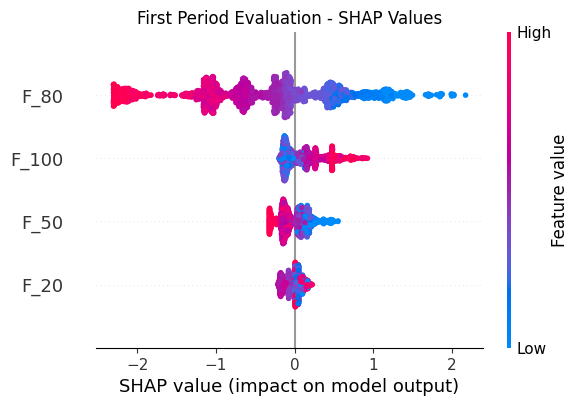

In [20]:
# Generate SHAP summary plot
shap.summary_plot(explanation_1, X_test_1.rename(columns = {"period_20": "F_20",
                                                            "period_50": "F_50",
                                                            "period_80": "F_80",
                                                            "period_100": "F_100"}), plot_size=(6, 4), show=False)

# Add title using matplotlib
plt.title("First Period Evaluation - SHAP Values")
plt.show()

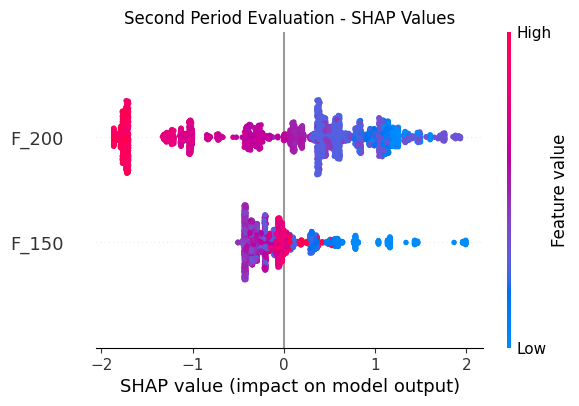

In [21]:
shap.summary_plot(explanation_2, X_test_2.rename(columns = {"period_200": "F_200",
                                                            "period_150": "F_150"}), plot_size = (6,4), show=False)

# Add title using matplotlib
plt.title("Second Period Evaluation - SHAP Values")
plt.show()

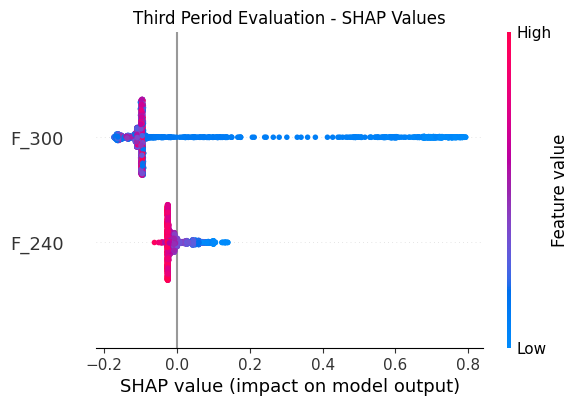

In [22]:
shap.summary_plot(explanation_3[:,:,1], X_test_3.rename(columns = {"period_300": "F_300",
                                                                   "period_240": "F_240"}), plot_size = (6,4), show=False)

# Add title using matplotlib
plt.title("Third Period Evaluation - SHAP Values")
plt.show()

# Models Performance Evaluation

In [18]:
#obtain y_prob of all evaluation periods
y_prob_1 = model_classifier_1.predict_proba(X_test_1)[:,1]
y_prob_2 = model_classifier_2.predict_proba(X_test_2)[:,1]
y_prob_3 = model_classifier_3.predict_proba(X_test_3)[:,1]

#create empty dataframes
roc_df_complete = pd.DataFrame()
calibration_curve_complete = pd.DataFrame()
df_proba_distribution_complete = pd.DataFrame()

#iterate over all evaluation periods
for y_test, y_prob, period in zip((y_test_1, y_test_2, y_test_3), (y_prob_1, y_prob_2, y_prob_3), ("First", "Second", "Third")):

    # --- ROC ---

    #obtain false positive rate and true positive rate, for each threshold
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    #calculate auc
    roc_auc = auc(fpr, tpr)

    #create data frame to plot
    roc_df = pd.DataFrame({'Evaluation Period': f"{period} (AUROC = {roc_auc:.2f})",
                        'False Positive Rate': fpr,
                        'True Positive Rate': tpr,
                        'Thresholds': thresholds})
    
    #concatenate the results
    roc_df_complete = pd.concat([roc_df_complete, roc_df], axis = 0)

    # --- CALIBRATION --- 

    # Compute calibration curve
    fraction_of_positives, mean_predicted_value= calibration_curve(y_test,
                                                                    y_prob,
                                                                    n_bins=10,
                                                                    strategy='uniform')

    # Create a DataFrame for the calibration curve
    calibration_df = pd.DataFrame({'Evaluation Period': f"{period}",
                                    'Mean Predicted Probability': mean_predicted_value,
                                    'Fraction of Positives': fraction_of_positives})
    
    #concatenate results
    calibration_curve_complete = pd.concat([calibration_curve_complete, calibration_df], axis = 0)

    # --- PROBABILITY DISTRIBUTION --- 

    #create dataframe
    df_proba_distribution = pd.DataFrame({'Evaluation Period': f"{period}",
                                        'Classification': y_test.late_project.values,
                                        'Probability': y_prob})
    #concatenate results
    df_proba_distribution_complete = pd.concat([df_proba_distribution_complete, df_proba_distribution], axis = 0)
    
print(roc_df_complete.head())
print(calibration_curve_complete.head())
print(df_proba_distribution_complete.head())

      Evaluation Period  False Positive Rate  True Positive Rate  Thresholds
0  First (AUROC = 0.78)             0.000000            0.000000         inf
1  First (AUROC = 0.78)             0.000000            0.006557    0.703563
2  First (AUROC = 0.78)             0.000000            0.009836    0.679423
3  First (AUROC = 0.78)             0.000456            0.009836    0.669778
4  First (AUROC = 0.78)             0.000456            0.022951    0.619690
  Evaluation Period  Mean Predicted Probability  Fraction of Positives
0             First                    0.052737               0.040471
1             First                    0.141764               0.134557
2             First                    0.239993               0.288000
3             First                    0.346995               0.349112
4             First                    0.436523               0.468085
  Evaluation Period  Classification  Probability
0             First               0     0.042340
1             

## AUROC

In [41]:
# #create ROC plot
# fig = px.line(roc_df_complete,
#               x='False Positive Rate',
#               y='True Positive Rate',
#               title=f'ROC Curve',
#               color = "Evaluation Period",
#               height = 600,
#               width = 1000,
#               color_discrete_sequence=px.colors.qualitative.Set1,)
              
# #add 0.5 line
# fig.add_shape(type='line',
#               line=dict(dash='dash'),
#               x0=0, x1=1,
#               y0=0, y1=1)

# #update layout
# fig.update_layout(
#     title={'font': {'size': 24}, 'x': 0.5},
#     xaxis_title={'font': {'size': 20}},
#     yaxis_title={'font': {'size': 20}},
#     xaxis={'tickfont': {'size': 16}},
#     yaxis={'tickfont': {'size': 16}},
#     legend=dict(
#         title='Evaluation Period',
#         font=dict(size=14),  # Increase the legend text size
#         title_font=dict(size=16)),  # Increase the legend title size,  # Increase legend text size

#     plot_bgcolor='white',  # Background color of the plot area
#     paper_bgcolor='white'  # Background color of the entire figure
# )
# fig.update_traces(
#     line=dict(width=2),  # Line width
# )

# # Add border by creating an external layout shape
# fig.add_shape(type="rect",
#     xref="paper", yref="paper",
#     x0=0, y0=0, x1=1, y1=1,
#     line=dict(color="lightgray", width=1.25),  # Border color and width
#     fillcolor="rgba(0,0,0,0)"  # No fill, transparent
# )

# fig.update_layout(
#     xaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
#     yaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
#     margin=dict(l=50, r=50, t=100, b=50),  # Margins for the plot
# )

In [37]:
#create ROC plot
fig = px.line(roc_df_complete,
              x='False Positive Rate',
              y='True Positive Rate',
              title=f'ROC Curve',
              color = "Evaluation Period",
              height = 600,
              width = 1000,
              color_discrete_sequence=['black', 'dimgray', 'gray']  # Define your custom colors
)

# Add 0.5 line
fig.add_shape(type='line',
              line=dict(dash='dash'),
              x0=0, x1=1,
              y0=0, y1=1)

# Update layout
fig.update_layout(
    title={'font': {'size': 24}, 'x': 0.5},
    xaxis_title={'font': {'size': 20}},
    yaxis_title={'font': {'size': 20}},
    xaxis={'tickfont': {'size': 16}},
    yaxis={'tickfont': {'size': 16}},
    legend=dict(
        title='Evaluation Period',
        font=dict(size=14),
        title_font=dict(size=16)
    ),
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Update traces with custom line styles
fig.update_traces(
    line=dict(width=2),  # Default line width
)

# Manually adjust each ROC curve's line style
for i, line_style in enumerate([{'dash': 'solid'}, {'dash': 'dash'}, {'dash': 'dot'}]):
    fig.data[i].update(line=dict(
        color=fig.data[i].line.color,  # Use the predefined colors
        dash=line_style['dash'],
        width=2 + (1 if line_style['dash'] == 'dot' else 0)  # Increase width for lighter lines
    ))

# Add border by creating an external layout shape
fig.add_shape(type="rect",
    xref="paper", yref="paper",
    x0=0, y0=0, x1=1, y1=1,
    line=dict(color="lightgray", width=1.25),
    fillcolor="rgba(0,0,0,0)"  # No fill, transparent
)

fig.update_layout(
    xaxis=dict(showgrid=True, gridcolor='lightgray'),
    yaxis=dict(showgrid=True, gridcolor='lightgray'),
    margin=dict(l=50, r=50, t=100, b=50)
)


## Calibration Curve

In [20]:
import warnings

# Suppress all warnings
warnings.filterwarnings("ignore")
# Plot calibration curve using Plotly Express
fig = px.line(calibration_curve_complete, x='Mean Predicted Probability', 
              y='Fraction of Positives',
            labels={'Mean Predicted Probability': 'Mean Predicted Probability', 'Fraction of Positives': 'Fraction of Positives'},
            title='Calibration Curve',
            color = "Evaluation Period",
            height = 600,
            width = 1000,
            color_discrete_sequence=px.colors.qualitative.Set1,)

#add 0.5 line
fig.add_shape(type='line',
             amorline=dict(dash='dash'),
              x0=0, x1=1,
              y0=0, y1=1)

#update layout
fig.update_layout(
    title={'font': {'size': 24}},
    xaxis_title={'font': {'size': 20}},
    yaxis_title={'font': {'size': 20}},
    xaxis={'tickfont': {'size': 16}},
    yaxis={'tickfont': {'size': 16}},
    legend=dict(
        title='Evaluation Period',
        font=dict(size=14),  # Increase the legend text size
        title_font=dict(size=16)),  # Increase the legend title size,  # Increase legend text size
)
fig.update_traces(
    line=dict(width=2),  # Line width
)

## Probability Distribution

In [42]:
# fig = px.histogram(df_proba_distribution_complete.replace({0: "On-time", 1: "Late"}),
#              facet_col = "Evaluation Period",
#              x = "Probability",
#              color = "Classification",
#              barmode = "overlay",
#              histnorm = "percent",
#              title = "Probability Distribution of the Predictions (in percent)",
#              )

# subplot_titles = fig.layout.annotations
# for i, annotation in enumerate(subplot_titles):
#     # Add the diagonal hash line to each subplot

#     annotation['font'] = dict(size=18)  # You can adjust the size as needed

# # Apply the xaxis and yaxis title and font to all subplots
# for axis in fig.layout:
#     if axis.startswith('xaxis'):
#         fig.layout[axis].title = { 'font': {'size': 20}}
#         fig.layout[axis].tickfont = {'size': 16}  # Set tick font size if needed
#     elif axis.startswith('yaxis'):
#         fig.layout[axis].title = { 'font': {'size': 20}}
#         fig.layout[axis].tickfont = {'size': 16}  # Set tick font size if needed

# #update layout
# fig.update_layout(
#     title={'font': {'size': 24}},
#     xaxis_title={'font': {'size': 20}},
#     yaxis_title={'font': {'size': 20}},
#     xaxis={'tickfont': {'size': 16}},
#     yaxis={'tickfont': {'size': 16}},
#     legend=dict(
#         font=dict(size=14),  # Increase the legend text size
#         title_font=dict(size=16)),  # Increase the legend title size,  # Increase legend text size
# )

# # fig.show()

In [72]:
# Adjusted color mapping for histogram with faceted subplots
fig = px.histogram(df_proba_distribution_complete.replace({0: "On-time", 1: "Late"}),
             facet_col="Evaluation Period",
             x="Probability",
             color="Classification",
             barmode="overlay",
             histnorm="percent",
             opacity = 0.5,
             title="Probability Distribution of the Predictions (in percent)",
             color_discrete_map={
                 "On-time": "black",
                 "Late": "dimgray"
             },
             )

# Update the subplot titles
subplot_titles = fig.layout.annotations
for i, annotation in enumerate(subplot_titles):
    annotation['font'] = dict(size=18)

# Apply x-axis and y-axis titles and fonts to all subplots
for i in range(1, len(fig.layout.annotations) + 1):
    # Apply grid and settings for x-axis
    fig.update_xaxes(title_text="Probability", title_font=dict(size=20), tickfont=dict(size=16),
                     showgrid=True, gridcolor="lightgray", row=1, col=i)
    # Apply y-axis settings only to the first column, with range increased to 80
    if i == 1:
        fig.update_yaxes(title_text="Percentage", title_font=dict(size=20), tickfont=dict(size=16),
                         range=[0, 81],  # Extend y-axis range to 80
                         showgrid=True, gridcolor="lightgray", row=1, col=i)
    else:
        fig.update_yaxes(showticklabels=False, range=[0, 81],  # Ensure consistent y-axis range
                         showgrid=True, gridcolor="lightgray", row=1, col=i)

# Update layout for background, title, and legend
fig.update_layout(
    title={'font': {'size': 24}, 'x': 0.5},  # Center the title
    legend=dict(
        title='Classification',
        font=dict(size=14),
        title_font=dict(size=16)
    ),
    plot_bgcolor='white',  # Set background to white
    paper_bgcolor='white'   # Set the paper background to white
)

# fig.show()


## Threshold Analysis

In [22]:
#create the confusion matrix dataframe
df_threshold_confusion_matrix = pd.DataFrame()

#iterate over each evaluation period
for period in df_proba_distribution_complete["Evaluation Period"].unique():

  #iterate over threshold value (from 0.05 until 0.95)
  for thr in np.arange(0.05, 1.0, 0.05):

    #copy original dataframe
    tmp_proba_distribution = df_proba_distribution_complete.loc[df_proba_distribution_complete["Evaluation Period"] == period].copy()

    #create threshold result, based on thr parameter
    tmp_proba_distribution["classification_thres"] = tmp_proba_distribution["Probability"] >= thr

    #create the confusion matrix parameter, with the result
    tmp_proba_distribution["confusion_matrix"] = np.where(
        (tmp_proba_distribution.classification_thres == 0) & (tmp_proba_distribution.Classification == 0),
        "TN", np.where(
        (tmp_proba_distribution.classification_thres == 1) & (tmp_proba_distribution.Classification == 1),
        "TP", np.where(
        (tmp_proba_distribution.classification_thres == 1) & (tmp_proba_distribution.Classification == 0),
        "FP", "FN"
        )))

    #count the values of the confusion matrix and convert it to dataframe
    tmp_confusion_matrix = pd.DataFrame(tmp_proba_distribution.confusion_matrix.value_counts(normalize = True))\
                              .reset_index()
    
    #create index columns
    tmp_confusion_matrix["Threshold"] = thr
    tmp_confusion_matrix["Evaluation Period"] = period

    #pivot table the dataframe
    tmp_confusion_matrix = pd.pivot_table(data = tmp_confusion_matrix, 
                            columns = ["confusion_matrix"],
                            values = "proportion",
                            index = ["Evaluation Period", "Threshold"],
                            fill_value = 0).reset_index()
    
    #drop column name
    tmp_confusion_matrix.columns.name = None

    #concatenate value
    df_threshold_confusion_matrix = pd.concat([df_threshold_confusion_matrix, tmp_confusion_matrix], axis = 0)
  
df_threshold_confusion_matrix.fillna(0, inplace = True)
df_threshold_confusion_matrix = df_threshold_confusion_matrix.round(2)
df_threshold_confusion_matrix.head(2)

,Evaluation Period,Threshold,FN,FP,TN,TP
0,First,0.05,0.01,0.61,0.26,0.12
0,First,0.10,0.02,0.36,0.52,0.10


In [23]:
fig = px.bar(df_threshold_confusion_matrix,
              x = "Threshold",
              y = ["TP", "FP", "TN", "FN"],
              facet_col = "Evaluation Period",
              title = "Confusion Matrix Threshold Analysis",
              text_auto = True,
              color_discrete_sequence=px.colors.qualitative.G10,
              width = 1800,
              height = 500)

# Update layout for legend, title, and subplot titles
fig.update_layout(
    title={'text': "Confusion Matrix Threshold Analysis", 'font': {'size': 24}},
    legend_title_text='Metric',  # Change legend title to 'Metric'
    legend={'title': {'font': {'size': 18}}, 'font': {'size': 14}},
    font={'size': 12}  # General font size for other elements
)

# Update x and y axis labels and font sizes
fig.update_xaxes(title_text='Threshold', title_font={'size': 20}, tickfont=dict(size=16))

# Link y-axes to avoid duplicate titles
fig.update_yaxes(title_font={'size': 20}, tickfont=dict(size=16), matches='y')

# Update subplot titles
for annotation in fig.layout.annotations:
    annotation['font'] = dict(size=18)

# Update text inside bars
fig.update_traces(textfont_size=20)

# Show the figure
fig.show()


In [24]:
fig = px.line(df_threshold_confusion_matrix,
              x = "Threshold",
              y = ["TP", "FP", "TN", "FN"],  # Metrics as y-values
              facet_col = "Evaluation Period",  # Faceting by Evaluation Period
              title = "Confusion Matrix Threshold Analysis",
              markers=True,  # Optional: Adds markers to the line
              color_discrete_sequence=px.colors.qualitative.G10,
              width = 1600,
              height = 500)

# Update layout for legend, title, and subplot titles
fig.update_layout(
    title={'text': "Confusion Matrix Threshold Analysis", 'font': {'size': 24}},
    legend_title_text='Metric',  # Change legend title to 'Metric'
    legend={'title': {'font': {'size': 18}}, 'font': {'size': 14}},
    font={'size': 12}  # General font size for other elements
)

# Update x and y axis labels and font sizes
fig.update_xaxes(
    title_text='Threshold', 
    title_font={'size': 20}, 
    tickfont=dict(size=16), 
    dtick=0.1,  # Set the tick interval to 0.1 for x-axis
    range=[0, 1]  # Ensure the range is from 0 to 1 for x-axis
)

fig.update_yaxes(
    # title_text='Value', 
    title_font={'size': 20}, 
    tickfont=dict(size=16), 
    dtick=0.1,  # Set the tick interval to 0.1 for y-axis
    range=[-0.05, 0.95],  # Ensure the range is from 0 to 1 for y-axis
    matches='y'  # Ensure y-axes are linked
)

# Update subplot titles
for annotation in fig.layout.annotations:
    annotation['font'] = dict(size=18)

# Show the figure
fig.show()


In [79]:
import plotly.express as px
import pandas as pd

# Reshape the data from wide to long format for easier customization in Plotly Express
df_long = pd.melt(df_threshold_confusion_matrix, id_vars=["Threshold", "Evaluation Period"], 
                  value_vars=["TP", "FP", "TN", "FN"], 
                  var_name="Metric", value_name="Value")

# Define custom gray shades, line dash styles, and symbols for the lines
custom_gray_shades = ["black", "dimgray", "gray", "lightgray"]
custom_line_dashes = ['solid', 'dash', 'dot', 'dashdot']
custom_symbols = ['circle', 'square', 'diamond', 'cross']  # Different shapes for each metric

# Create the line plot using the long format data
fig = px.line(df_long,
              x="Threshold",
              y="Value",
              color="Metric",  # Use the reshaped "Metric" column for color
              line_dash="Metric",  # Use the reshaped "Metric" column for different line styles
              symbol="Metric",  # Use the reshaped "Metric" column for different symbols
              facet_col="Evaluation Period",  # Faceting by Evaluation Period
              title="Confusion Matrix Threshold Analysis",
              markers=True,  # Adds markers to the line
              color_discrete_sequence=custom_gray_shades,  # Custom gray shades
              line_dash_sequence=custom_line_dashes,  # Custom line dashes
              symbol_sequence=custom_symbols,  # Custom symbols for each metric
              width=1600,
              height=500)

# Update layout for the title, legend, and background
fig.update_layout(
    title={'text': "Confusion Matrix Threshold Analysis", 'font': {'size': 24}, 'x': 0.5},  # Centered title
    legend_title_text='Metric',  # Change legend title to 'Metric'
    legend={'title': {'font': {'size': 18}}, 'font': {'size': 14}},
    plot_bgcolor='white',  # Set background to white
    paper_bgcolor='white',  # Set paper background to white
    font={'size': 12}  # General font size for other elements
)

# Update x and y axis labels and font sizes, and apply to all subplots
fig.update_xaxes(
    title_text='Threshold', 
    title_font={'size': 20}, 
    tickfont=dict(size=16), 
    dtick=0.1,  # Set the tick interval to 0.1 for x-axis
    range=[0, 1],  # Ensure the range is from 0 to 1 for x-axis
    showgrid=True, gridcolor='lightgray'
)

fig.update_yaxes(
    title_text='Value',  # Set title only for the first column
    title_font={'size': 20}, 
    tickfont=dict(size=16), 
    dtick=0.1,  # Set the tick interval to 0.1 for y-axis
    range=[-0.05, 0.95],  # Ensure the range is from 0 to 1 for y-axis
    showgrid=True, gridcolor='lightgray',
    matches='y',  # Ensure all y-axes are linked, avoiding duplicate y-axis titles
    showticklabels=True
)

# Remove y-axis titles for all but the first facet
for i in range(1, len(fig.layout.annotations)):
    fig.layout['yaxis' + str(i+1)].title.text = ''

# Update subplot titles
for annotation in fig.layout.annotations:
    annotation['font'] = dict(size=18)

# Show the figure
fig.show()


# Calibrated Models Performance Evaluation

## Calibrate the Models

In [25]:
# #create calibrated models
# calibrated_1 = CalibratedClassifierCV(model_classifier_1, cv=5, method = "sigmoid")
# calibrated_1.fit(X_train_1, y_train_1)

# calibrated_2 = CalibratedClassifierCV(model_classifier_2, cv=5, method = "sigmoid")
# calibrated_2.fit(X_train_2, y_train_2)

# calibrated_3 = CalibratedClassifierCV(model_classifier_3, cv=5, method = "sigmoid")
# calibrated_3.fit(X_train_3, y_train_3)

In [26]:
# #obtain y_prob of all evaluation periods
# y_prob_1 = calibrated_1.predict_proba(X_test_1)[:,1]
# y_prob_2 = calibrated_2.predict_proba(X_test_2)[:,1]
# y_prob_3 = calibrated_3.predict_proba(X_test_3)[:,1]

# #create empty dataframes
# roc_df_complete = pd.DataFrame()
# calibration_curve_complete = pd.DataFrame()
# df_proba_distribution_complete = pd.DataFrame()

# #iterate over all evaluation periods
# for y_test, y_prob, period in zip((y_test_1, y_test_2, y_test_3), (y_prob_1, y_prob_2, y_prob_3), ("First", "Second", "Third")):

#     # --- ROC ---

#     #obtain false positive rate and true positive rate, for each threshold
#     fpr, tpr, thresholds = roc_curve(y_test, y_prob)

#     #calculate auc
#     roc_auc = auc(fpr, tpr)

#     #create data frame to plot
#     roc_df = pd.DataFrame({'Evaluation Period': f"{period} (AUROC = {roc_auc:.2f})",
#                         'False Positive Rate': fpr,
#                         'True Positive Rate': tpr,
#                         'Thresholds': thresholds})
    
#     #concatenate the results
#     roc_df_complete = pd.concat([roc_df_complete, roc_df], axis = 0)

#     # --- CALIBRATION --- 

#     # Compute calibration curve
#     fraction_of_positives, mean_predicted_value= calibration_curve(y_test,
#                                                                     y_prob,
#                                                                     n_bins=5,
#                                                                     strategy='uniform')

#     # Create a DataFrame for the calibration curve
#     calibration_df = pd.DataFrame({'Evaluation Period': f"{period}",
#                                     'Mean Predicted Probability': mean_predicted_value,
#                                     'Fraction of Positives': fraction_of_positives})
    
#     #concatenate results
#     calibration_curve_complete = pd.concat([calibration_curve_complete, calibration_df], axis = 0)

#     # --- PROBABILITY DISTRIBUTION --- 

#     #create dataframe
#     df_proba_distribution = pd.DataFrame({'Evaluation Period': f"{period}",
#                                         'Classification': y_test.late_project.values,
#                                         'Probability': y_prob})
#     #concatenate results
#     df_proba_distribution_complete = pd.concat([df_proba_distribution_complete, df_proba_distribution], axis = 0)
    
# print(roc_df_complete.head())
# print(calibration_curve_complete.head())
# print(df_proba_distribution_complete.head())

## AUROC

In [27]:
# #create ROC plot
# fig = px.line(roc_df_complete,
#               x='False Positive Rate',
#               y='True Positive Rate',
#               title=f'ROC Curve',
#               color = "Evaluation Period",
#               height = 600,
#               width = 1000,
#               color_discrete_sequence=px.colors.qualitative.Set1,)
              

# #add 0.5 line
# fig.add_shape(type='line',
#               line=dict(dash='dash'),
#               x0=0, x1=1,
#               y0=0, y1=1)

# #update layout
# fig.update_layout(
#     title={'font': {'size': 24}},
#     xaxis_title={'font': {'size': 20}},
#     yaxis_title={'font': {'size': 20}},
#     xaxis={'tickfont': {'size': 16}},
#     yaxis={'tickfont': {'size': 16}},
#     legend=dict(
#         title='Evaluation Period',
#         font=dict(size=14),  # Increase the legend text size
#         title_font=dict(size=16)),  # Increase the legend title size,  # Increase legend text size
# )
# fig.update_traces(
#     line=dict(width=2),  # Line width
# )

## Calibration Curve

In [28]:
# # Suppress all warnings
# warnings.filterwarnings("ignore")
# # Plot calibration curve using Plotly Express
# fig = px.line(calibration_curve_complete, x='Mean Predicted Probability', 
#               y='Fraction of Positives',
#             labels={'Mean Predicted Probability': 'Mean Predicted Probability', 'Fraction of Positives': 'Fraction of Positives'},
#             title='Calibration Curve',
#             color = "Evaluation Period",
#             height = 600,
#             width = 1000,
#             color_discrete_sequence=px.colors.qualitative.Set1,)

# #add 0.5 line
# fig.add_shape(type='line',
#               line=dict(dash='dash'),
#               x0=0, x1=1,
#               y0=0, y1=1)

# #update layout
# fig.update_layout(
#     title={'font': {'size': 24}},
#     xaxis_title={'font': {'size': 20}},
#     yaxis_title={'font': {'size': 20}},
#     xaxis={'tickfont': {'size': 16}},
#     yaxis={'tickfont': {'size': 16}},
#     legend=dict(
#         title='Evaluation Period',
#         font=dict(size=14),  # Increase the legend text size
#         title_font=dict(size=16)),  # Increase the legend title size,  # Increase legend text size
# )
# fig.update_traces(
#     line=dict(width=2),  # Line width
# )

In [29]:
# px.histogram(df_proba_distribution_complete,
#              facet_col = "Evaluation Period",
#              x = "Probability",
#              color = "Classification",
#              barmode = "overlay",
#              histnorm = "percent",
#              title = "Histogram of Probability Distribution (in percent)",
#              )

In [30]:
# Models 